# 32. 시계열 딥러닝 이상탐지 — LSTM / CNN / CNN-LSTM 오토인코더 × window 실험

2022 우수작의 **'LSTM → CNN-LSTM, window 1~10분'** 실험을 우리 데이터에 맞게 바꾼 것.

- 불량 라벨이 너무 적어(CN7 15, RG3 32) **정상 생산 시퀀스만 학습** → 복원오차 = 이상 점수
- 학습 데이터·평가 방식은 최종 모델(Mahalanobis)과 동일 → 차이는 **과거 W샷 시퀀스를 통째로 보느냐**뿐
- window W = 10 / 20 / 30 / 50샷, 점수 = `last`(지금 샷) / `win`(창 전체 = 구간 이상)
- 핵심 질문: **긴 창(W=50)의 `win` 점수가 CN7 가스 에피소드를 잡는가?**

**준비**: `20a_final_train` → `20b_final_test`를 먼저 실행 (`outputs/final_model/{p}_train_features.csv`, `{p}_scores.csv` 필요)
`pip install torch` (CPU 버전으로 충분)

In [1]:
%pip install torch --index-url https://download.pytorch.org/whl/cpu
%pip install lightgbm catboost shap imbalanced-learn
import pandas as pd
pd.set_option('display.max_columns', 60); pd.set_option('display.width', 250)
from plot_style import set_style; set_style()
import seq_ae as S
import torch; print('torch', torch.__version__, '| GPU:', torch.cuda.is_available())

Looking in indexes: https://download.pytorch.org/whl/cpu
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
torch 2.14.1+cpu | GPU: False


## 0. 빠른 점검 (1~2분) — 에러 없이 돌아가는지만 확인
창 20, 시드 1개, CN7만. 문제 없으면 1번으로.

In [2]:
Q = S.run(products=('cn7',), windows=(20,), seeds=(0,), out_dir='./outputs/seq_ae_quick')
Q['summary'][['제품', '모델', '① AP', '② AP', '② AP_가스', '② AP_미성형', 'ΔAP(②, vs 최종)', 'ΔAP 95%CI']]

[cn7] cn7_train_features.csv 없음 → 저장된 모델 기준값으로 학습 데이터 다시 생성 (수 분)
[cn7|free] reference 학습 1,465샷 / 검증 3,714샷 | labeled 1,979샷 | 변수 17개
    lstm_ae seed0: 21 epoch, 검증 손실 1.2623
  [cn7|free] lstm_ae W=20 완료 (7초)
    cnn_ae seed0: 60 epoch, 검증 손실 0.6560
  [cn7|free] cnn_ae W=20 완료 (8초)
    cnn_lstm_ae seed0: 34 epoch, 검증 손실 1.2576
  [cn7|free] cnn_lstm_ae W=20 완료 (9초)


,제품,모델,① AP,② AP,② AP_가스,② AP_미성형,"ΔAP(②, vs 최종)",ΔAP 95%CI
0,cn7,M_maha_free (최종),0.372833,0.211572,0.007457,0.750533,NaN,NaN
1,cn7,lstm_ae|W20|last,0.244132,0.106364,0.007336,0.359201,-0.105208,"[-0.178, +0.002]"
2,cn7,lstm_ae|W20|win,0.117498,0.048194,0.031325,0.030681,-0.163378,"[-0.355, +0.029]"
3,cn7,cnn_ae|W20|last,0.377239,0.143060,0.010304,0.479853,-0.068512,"[-0.134, +0.011]"
4,cn7,cnn_ae|W20|win,0.094754,0.045628,0.030258,0.030406,-0.165944,"[-0.353, +0.026]"
5,cn7,cnn_lstm_ae|W20|last,0.242226,0.105125,0.006385,0.359481,-0.106447,"[-0.179, +0.001]"
6,cn7,cnn_lstm_ae|W20|win,0.107487,0.039767,0.024754,0.030344,-0.171804,"[-0.361, +0.022]"


## 1. 본 실험 — 3모델 × 창 4개 × 시드 3개 × 제품 2개
CPU 기준 수십 분 걸릴 수 있음. 결과는 `outputs/seq_ae/`에 저장.

In [3]:
R = S.run(products=('cn7', 'rg3'), windows=S.WINDOWS, seeds=S.SEEDS, inputs=('free',))

[cn7|free] reference 학습 1,465샷 / 검증 3,714샷 | labeled 1,979샷 | 변수 17개
    lstm_ae seed0: 60 epoch, 검증 손실 0.8288
    lstm_ae seed1: 60 epoch, 검증 손실 0.7980
    lstm_ae seed2: 60 epoch, 검증 손실 0.8309
  [cn7|free] lstm_ae W=10 완료 (30초)
    cnn_ae seed0: 60 epoch, 검증 손실 0.4977
    cnn_ae seed1: 60 epoch, 검증 손실 0.4930
    cnn_ae seed2: 60 epoch, 검증 손실 0.5182
  [cn7|free] cnn_ae W=10 완료 (11초)
    cnn_lstm_ae seed0: 60 epoch, 검증 손실 0.8147
    cnn_lstm_ae seed1: 60 epoch, 검증 손실 0.8603
    cnn_lstm_ae seed2: 60 epoch, 검증 손실 0.8977
  [cn7|free] cnn_lstm_ae W=10 완료 (112초)
    lstm_ae seed0: 21 epoch, 검증 손실 1.2623
    lstm_ae seed1: 23 epoch, 검증 손실 1.2543
    lstm_ae seed2: 30 epoch, 검증 손실 1.2558
  [cn7|free] lstm_ae W=20 완료 (16초)
    cnn_ae seed0: 60 epoch, 검증 손실 0.6560
    cnn_ae seed1: 45 epoch, 검증 손실 0.6517
    cnn_ae seed2: 60 epoch, 검증 손실 0.6382
  [cn7|free] cnn_ae W=20 완료 (11초)
    cnn_lstm_ae seed0: 34 epoch, 검증 손실 1.2576
    cnn_lstm_ae seed1: 25 epoch, 검증 손실 1.2672
    cnn_lstm_ae seed2: 24

## 2. 한눈 표 — 최종 모델 대비
- `ΔAP 95%CI`가 0을 넘어야(유의하게 좋음 = O) '시계열 딥러닝이 낫다'고 말할 수 있음
- 설정이 24개라 하나쯤은 우연히 좋아 보일 수 있음

In [4]:
cols = ['제품', '모델', '① AP', '① 상위10%', '② AP', '② AP 95%CI', '② AP_가스', '② AP_미성형',
        'Run별 상위10% 가스', 'Run별 상위10% 미성형', 'q0.999 경보', 'q0.999 TP', 'q0.999 가스', 'q0.999 미성형',
        'ΔAP(②, vs 최종)', 'ΔAP 95%CI', 'P(최종보다 좋음)', '유의하게 좋음', '학습 시간(초, 시드합)']
for p in ('cn7', 'rg3'):
    print(f'===== {p.upper()} (② AP 순) =====')
    display(R['summary'].query('제품 == @p')[cols].sort_values('② AP', ascending=False).round(3))

===== CN7 (② AP 순) =====


,제품,모델,① AP,① 상위10%,② AP,② AP 95%CI,② AP_가스,② AP_미성형,Run별 상위10% 가스,Run별 상위10% 미성형,q0.999 경보,q0.999 TP,q0.999 가스,q0.999 미성형,"ΔAP(②, vs 최종)",ΔAP 95%CI,P(최종보다 좋음),유의하게 좋음,"학습 시간(초, 시드합)"
0,cn7,M_maha_free (최종),0.373,8/17,0.212,"[0.011, 0.416]",0.007,0.751,1/11,3/4,8,3,0,3,NaN,NaN,NaN,NaN,NaN
15,cn7,cnn_ae|W30|last,0.375,7/17,0.174,"[0.013, 0.390]",0.010,0.605,0/11,3/4,5,3,0,3,-0.037,"[-0.097, +0.006]",0.335,-,10.259
3,cn7,cnn_ae|W10|last,0.381,7/17,0.147,"[0.018, 0.370]",0.012,0.480,1/11,3/4,18,3,0,3,-0.065,"[-0.131, +0.020]",0.365,-,11.254
9,cn7,cnn_ae|W20|last,0.380,7/17,0.145,"[0.018, 0.364]",0.012,0.480,1/11,3/4,7,3,0,3,-0.066,"[-0.133, +0.014]",0.362,-,10.693
5,cn7,cnn_lstm_ae|W10|last,0.373,7/17,0.140,"[0.013, 0.352]",0.008,0.481,1/11,3/4,6,3,0,3,-0.072,"[-0.138, +0.006]",0.229,-,111.594
1,cn7,lstm_ae|W10|last,0.371,7/17,0.139,"[0.011, 0.354]",0.007,0.480,1/11,3/4,7,3,0,3,-0.073,"[-0.137, +0.004]",0.198,-,29.521
21,cn7,cnn_ae|W50|last,0.344,7/17,0.114,"[0.011, 0.336]",0.008,0.386,0/11,3/4,3,2,0,2,-0.098,"[-0.176, +0.003]",0.097,-,24.806
17,cn7,cnn_lstm_ae|W30|last,0.249,7/17,0.109,"[0.012, 0.346]",0.009,0.359,1/11,3/4,8,3,0,3,-0.103,"[-0.176, +0.005]",0.138,-,123.131
7,cn7,lstm_ae|W20|last,0.248,7/17,0.109,"[0.013, 0.344]",0.008,0.360,1/11,3/4,7,3,0,3,-0.103,"[-0.176, +0.005]",0.136,-,15.630
11,cn7,cnn_lstm_ae|W20|last,0.245,7/17,0.107,"[0.012, 0.342]",0.008,0.359,1/11,3/4,7,3,0,3,-0.104,"[-0.178, +0.003]",0.109,-,17.277


===== RG3 (② AP 순) =====


,제품,모델,① AP,① 상위10%,② AP,② AP 95%CI,② AP_가스,② AP_미성형,Run별 상위10% 가스,Run별 상위10% 미성형,q0.999 경보,q0.999 TP,q0.999 가스,q0.999 미성형,"ΔAP(②, vs 최종)",ΔAP 95%CI,P(최종보다 좋음),유의하게 좋음,"학습 시간(초, 시드합)"
33,rg3,lstm_ae|W20|win,0.019,1/25,0.107,"[0.060, 0.215]",0.090,0.039,1/22,1/10,0,0,0,0,0.044,"[-0.009, +0.138]",0.937,-,56.128
37,rg3,cnn_lstm_ae|W20|win,0.020,0/25,0.096,"[0.057, 0.185]",0.074,0.038,0/22,0/10,0,0,0,0,0.033,"[-0.011, +0.107]",0.919,-,130.425
41,rg3,cnn_ae|W30|win,0.022,1/25,0.087,"[0.056, 0.170]",0.075,0.025,1/22,0/10,0,0,0,0,0.023,"[-0.020, +0.095]",0.852,-,6.331
39,rg3,lstm_ae|W30|win,0.022,1/25,0.086,"[0.056, 0.169]",0.072,0.026,1/22,1/10,0,0,0,0,0.022,"[-0.019, +0.090]",0.860,-,16.829
43,rg3,cnn_lstm_ae|W30|win,0.022,1/25,0.084,"[0.056, 0.163]",0.070,0.026,1/22,1/10,0,0,0,0,0.020,"[-0.020, +0.079]",0.839,-,14.083
35,rg3,cnn_ae|W20|win,0.021,2/25,0.083,"[0.057, 0.142]",0.062,0.031,2/22,1/10,0,0,0,0,0.019,"[-0.019, +0.071]",0.834,-,10.897
31,rg3,cnn_lstm_ae|W10|win,0.019,1/25,0.071,"[0.052, 0.124]",0.048,0.034,2/22,1/10,0,0,0,0,0.007,"[-0.027, +0.054]",0.688,-,162.315
47,rg3,cnn_ae|W50|win,0.025,3/25,0.071,"[0.052, 0.125]",0.048,0.034,0/22,1/10,0,0,0,0,0.007,"[-0.034, +0.058]",0.662,-,10.165
29,rg3,cnn_ae|W10|win,0.023,3/25,0.069,"[0.052, 0.110]",0.051,0.026,2/22,1/10,9,0,0,0,0.006,"[-0.027, +0.041]",0.647,-,14.909
48,rg3,cnn_lstm_ae|W50|last,0.020,1/25,0.068,"[0.047, 0.148]",0.061,0.018,2/22,1/10,0,0,0,0,0.004,"[-0.015, +0.057]",0.620,-,71.928


## 3. 창 크기별 성능 (2022 'window size 실험' 표의 대응)
실선 = `win`(구간), 점선 = `last`(지금 샷), 검은 가로선 = 최종 모델

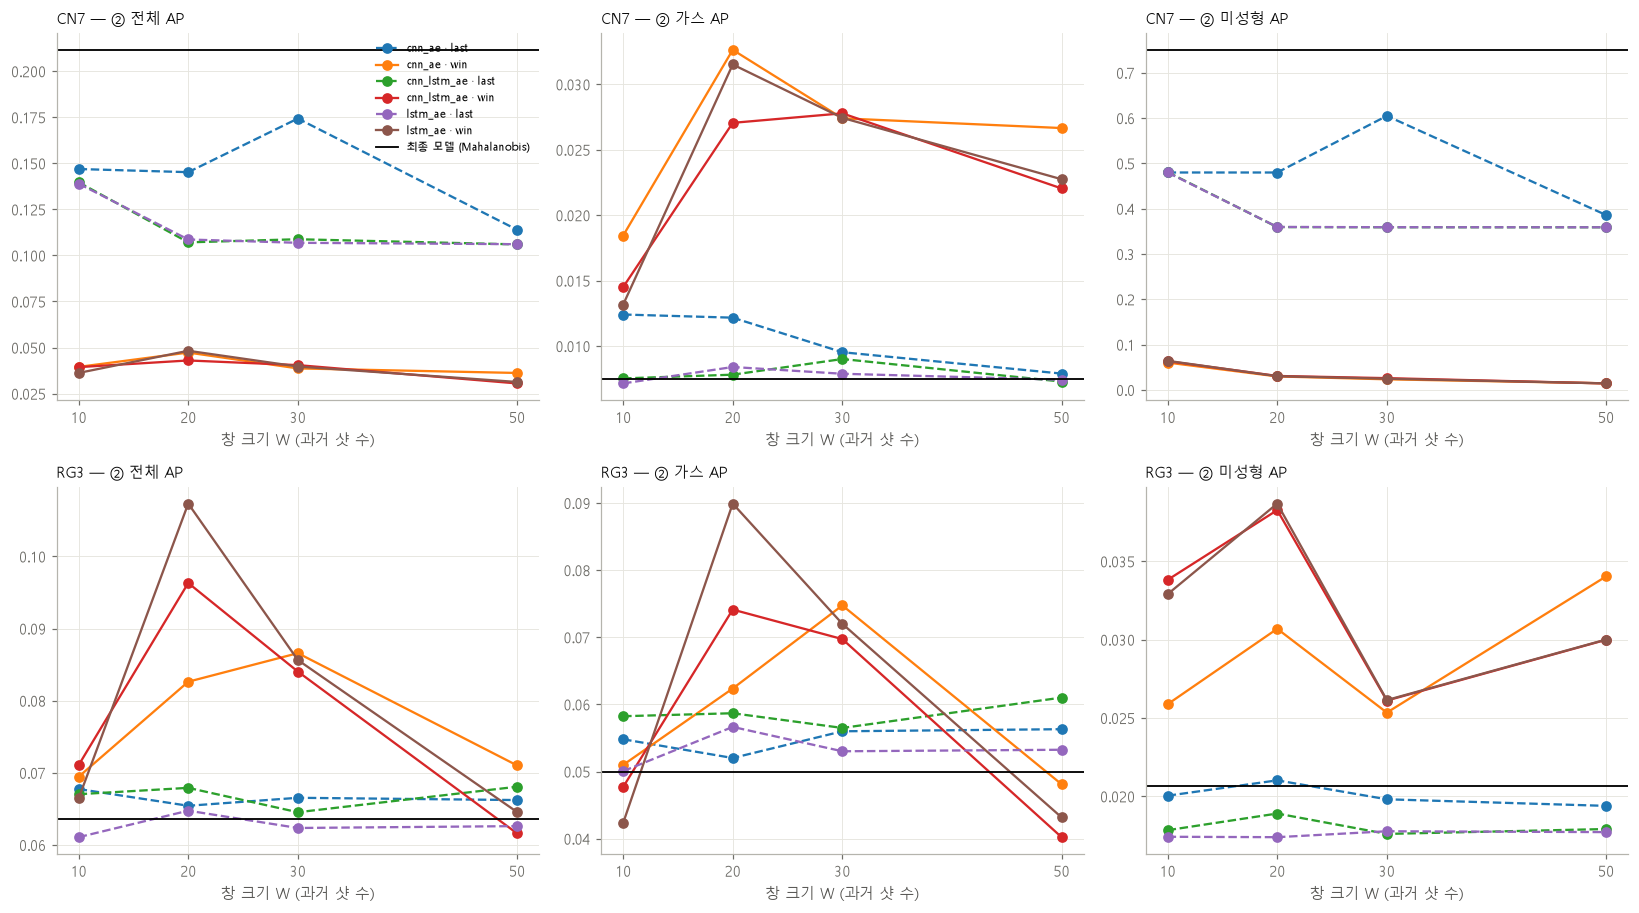

In [5]:
S.plot_windows(R, save='./outputs/seq_ae/window_ap.png')

In [6]:
# 창 × 모델 표 (② AP) — 발표 표로 바로 쓰기
for p in ('cn7', 'rg3'):
    s = R['summary'].query('제품 == @p and arch != "maha"').copy()
    s['점수'] = s['모델'].str.split('|').str[2]
    print(f'===== {p.upper()} ② AP =====')
    display(s.pivot_table(index=['arch', '점수'], columns='창', values='② AP').round(3))
    print(f'===== {p.upper()} ② 가스 AP =====')
    display(s.pivot_table(index=['arch', '점수'], columns='창', values='② AP_가스').round(3))

===== CN7 ② AP =====


창                  10.0   20.0   30.0   50.0
arch        점수                              
cnn_ae      last  0.147  0.145  0.174  0.114
            win   0.039  0.047  0.039  0.036
cnn_lstm_ae last  0.140  0.107  0.109  0.106
            win   0.039  0.043  0.040  0.031
lstm_ae     last  0.139  0.109  0.107  0.106
            win   0.036  0.048  0.040  0.031

===== CN7 ② 가스 AP =====


창                  10.0   20.0   30.0   50.0
arch        점수                              
cnn_ae      last  0.012  0.012  0.010  0.008
            win   0.018  0.033  0.027  0.027
cnn_lstm_ae last  0.008  0.008  0.009  0.007
            win   0.014  0.027  0.028  0.022
lstm_ae     last  0.007  0.008  0.008  0.007
            win   0.013  0.032  0.027  0.023

===== RG3 ② AP =====


창                  10.0   20.0   30.0   50.0
arch        점수                              
cnn_ae      last  0.068  0.065  0.067  0.066
            win   0.069  0.083  0.087  0.071
cnn_lstm_ae last  0.067  0.068  0.065  0.068
            win   0.071  0.096  0.084  0.062
lstm_ae     last  0.061  0.065  0.062  0.063
            win   0.066  0.107  0.086  0.065

===== RG3 ② 가스 AP =====


창                  10.0   20.0   30.0   50.0
arch        점수                              
cnn_ae      last  0.055  0.052  0.056  0.056
            win   0.051  0.062  0.075  0.048
cnn_lstm_ae last  0.058  0.059  0.056  0.061
            win   0.048  0.074  0.070  0.040
lstm_ae     last  0.050  0.057  0.053  0.053
            win   0.042  0.090  0.072  0.043

## 4. CN7 가스 집중 Run — 구간 점수가 가스 에피소드에서 올라오나

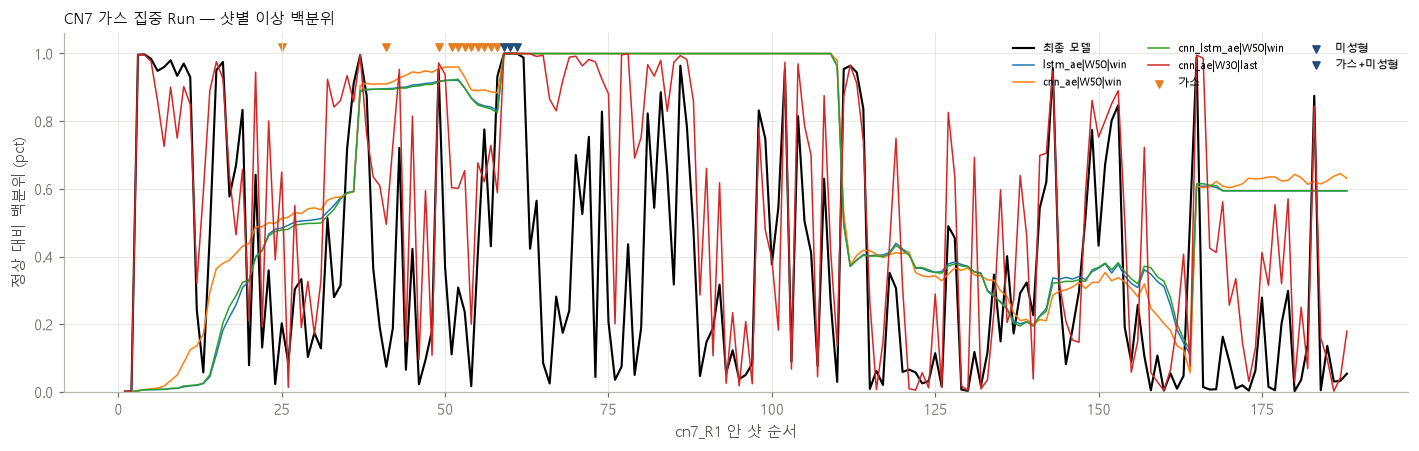

In [7]:
S.plot_r1(R, 'cn7', save='./outputs/seq_ae/cn7_r1_pct.png')

## 5. q 임계값 경보 (정상 오경보율 가정별)

In [8]:
best = {p: R['summary'].query('제품 == @p and arch != "maha"').sort_values('② AP', ascending=False)['모델'].iloc[0]
        for p in ('cn7', 'rg3')}
print('제품별 ② AP 최고 설정:', best)
th = R['threshold']
for p in ('cn7', 'rg3'):
    display(th[(th['제품'] == p) & th['모델'].isin([S.BASELINE, best[p]])]
            [['모델', 'q', '경보 수', 'TP', 'FP', 'Precision', 'Recall', '가스 탐지', '미성형계열 탐지']].round(3))

제품별 ② AP 최고 설정: {'cn7': 'cnn_ae|W30|last', 'rg3': 'lstm_ae|W20|win'}


,모델,q,경보 수,TP,FP,Precision,Recall,가스 탐지,미성형계열 탐지
0,M_maha_free (최종),0.950,105,4,101,0.038,0.267,1,3
1,M_maha_free (최종),0.980,45,3,42,0.067,0.200,0,3
2,M_maha_free (최종),0.990,29,3,26,0.103,0.200,0,3
3,M_maha_free (최종),0.995,19,3,16,0.158,0.200,0,3
4,M_maha_free (최종),0.999,8,3,5,0.375,0.200,0,3
75,cnn_ae|W30|last,0.950,107,4,103,0.037,0.267,1,3
76,cnn_ae|W30|last,0.980,64,3,61,0.047,0.200,0,3
77,cnn_ae|W30|last,0.990,48,3,45,0.062,0.200,0,3
78,cnn_ae|W30|last,0.995,33,3,30,0.091,0.200,0,3
79,cnn_ae|W30|last,0.999,5,3,2,0.600,0.200,0,3


,모델,q,경보 수,TP,FP,Precision,Recall,가스 탐지,미성형계열 탐지
125,M_maha_free (최종),0.950,45,3,42,0.067,0.094,3,0
126,M_maha_free (최종),0.980,20,1,19,0.050,0.031,1,0
127,M_maha_free (최종),0.990,9,0,9,0.000,0.000,0,0
128,M_maha_free (최종),0.995,6,0,6,0.000,0.000,0,0
129,M_maha_free (최종),0.999,3,0,3,0.000,0.000,0,0
165,lstm_ae|W20|win,0.950,16,2,14,0.125,0.062,2,0
166,lstm_ae|W20|win,0.980,2,1,1,0.500,0.031,1,0
167,lstm_ae|W20|win,0.990,0,0,0,0.000,0.000,0,0
168,lstm_ae|W20|win,0.995,0,0,0,0.000,0.000,0,0
169,lstm_ae|W20|win,0.999,0,0,0,0.000,0.000,0,0


## 6. (선택) 원값 21개 입력 — 2022의 '파생변수 유무' 실험
파생변수 없이 원값 시퀀스만 넣었을 때. 시간이 걸리니 필요할 때만.

In [9]:
# R_raw = S.run(products=('cn7', 'rg3'), inputs=('raw',), out_dir='./outputs/seq_ae_raw')
# display(R_raw['summary'][cols].round(3))